# Exploratory Data Analysis for Outfield Players

**Question to answer:** 

How should outfield-player performance be represented in the Player of the Season scoring framework?

**Objective:**

- Understand the distribution and characteristics of outfield-player performance features.
  
- Identify redundant and highly correlated variables within and across performance categories, with special focus to multicollinearity. Collinearity is very much expected because outfield players span attacking, creative, defensive, and disciplinary metrics simultaneously. 

- Segmentation analysis by position (forwards, midfielders, defenders) to determine whether feature screeing should be position-specific or applied similarly across all outfield-players. 

- Compare raw counting stats against per-90 stats and possession-adjusted equivalents to assess how playing time and role distort raw metrics across positions.

- Examine how team context influences individual output, to separate individual quality signal from team-driven inflation.
  
- Determine which features should be retained, removed, or combined based on the findings above.
  
- Define the outfield-player performance categories to be used during feature engineering.
  
- Produce a final POTSI feature engineering ready categorized outfield feature inventory that is tagged by retain/exclude decision and reasoning.

In [75]:
from pathlib import Path
import os

ROOT = Path().resolve().parent
os.chdir(ROOT)

PROCESSED = ROOT / "data" / "processed"

In [76]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [77]:
from utils.plotting import (
    PRIMARY,
    SECONDARY,
    ACCENT,
    MEAN_COLOR,
    MEDIAN_COLOR,
    HIST_BINS,
    set_plot_theme,
    style_plot,
)

from utils.correlation_plots import corr_heatmap_plot, investigate_correlation_pair

# Setting project theme
set_plot_theme()

## Data Audit

In [78]:
df = pd.read_parquet(PROCESSED / "outfield_players.parquet")

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\data\\processed\\outfield_players.parquet'

In [ ]:
df.head()

,Player,Nation,Squad,Age,Born,matches_played,starts,90s_played,goals_fbref,goals_assists,...,pass_perc,total_final_third_passes,successful_final_third_passes,ft_pass_perc,op_crosses,successful_op_crosses,cross_perc,through_balls,successful_through_balls,through_ball_perc
0,Brenden Aaronson,USA,Leeds United,24,2000,37.0,30.0,27.2,4.0,9.0,...,81.14,257,192,74.71,36,10,27.78,6,3,50.0
5,Tyler Adams,USA,AFC Bournemouth,26,1999,25.0,21.0,19.7,2.0,4.0,...,87.13,227,181,79.74,3,2,66.67,2,1,50.0
8,Amine Adli,MAR,AFC Bournemouth,25,2000,31.0,10.0,12.2,3.0,4.0,...,77.24,183,129,70.49,25,2,8.00,3,0,0.0
9,Emmanuel Agbadou,CIV,Wolverhampton Wanderers,28,1997,14.0,12.0,12.2,0.0,0.0,...,83.00,137,74,54.01,14,4,28.57,2,1,50.0
11,Ola Aina,NGA,Nottingham Forest,28,1996,18.0,18.0,17.6,0.0,0.0,...,84.74,171,133,77.78,38,7,18.42,0,0,0.0


In [ ]:
df.shape

(316, 102)

In [ ]:
df.dtypes

Player                       object
Nation                       object
Squad                        object
Age                          object
Born                         object
                             ...   
successful_op_crosses         int64
cross_perc                  float64
through_balls                 int64
successful_through_balls      int64
through_ball_perc           float64
Length: 102, dtype: object

In [ ]:
df.isnull().sum().sort_values(ascending=False)

Player                      0
Nation                      0
Squad                       0
Age                         0
Born                        0
                           ..
successful_op_crosses       0
cross_perc                  0
through_balls               0
successful_through_balls    0
through_ball_perc           0
Length: 102, dtype: int64

In [ ]:
df["Player"].nunique()

316

In [ ]:
df["Player"].duplicated().sum()

np.int64(0)

In [ ]:
df["Squad"].nunique()

20

In [ ]:
df.columns.to_list()

['Player',
 'Nation',
 'Squad',
 'Age',
 'Born',
 'matches_played',
 'starts',
 '90s_played',
 'goals_fbref',
 'goals_assists',
 'non_penalty_goals',
 'penalty_kicks_made',
 'penalty_kicks_attempted',
 'goals_per90',
 'assists_per90',
 'goals_assists_per90',
 'non_penalty_goals_per90',
 'non_penalty_goals_assists_per90',
 'shots_on_target_pct',
 'shots_per90',
 'goals_per_shot',
 'goals_per_shot_on_target',
 'shots_on_target_per90',
 'second_yellow_card',
 'crosses',
 'tackles_won',
 'fouls_drawn',
 'own_goals',
 'points_per_match',
 'goals_allowed_on_pitch',
 'plus_minus_per90',
 'goals_scored_on_pitch',
 'minutes_per_start',
 'plus_minus',
 'minutes_per_sub',
 'unused_sub',
 'minutes_pct',
 'complete_matches',
 'plus_minus_net_per90',
 'minutes_per_match',
 'sub_appearances',
 'mins_played',
 'xg',
 'goals_vs_xg',
 'shots',
 'shots_on_target_analyst',
 'shot_conv',
 'xg_per_shot',
 'squad_position',
 'np_goals',
 'np_xg',
 'np_goals_vs_xg',
 'np_shots',
 'np_shots_on_target',
 'np_sh

## Feature Scoping

Before analyzing feature distributions and relationships, the dataset was reviewed to separate identifier and demographic columns from genuine performance metrics. In order to limit further structural and correlation-based screening to the player's performance feature set, columns that describe the player rather than their performance were either dropped or kept separately as non-analytical context. 

In [ ]:
metadata_cols = ["Player", "Squad", "squad_position"]
df[metadata_cols].head()

,Player,Squad,squad_position
0,Brenden Aaronson,Leeds United,Midfielder
5,Tyler Adams,AFC Bournemouth,Midfielder
8,Amine Adli,AFC Bournemouth,Forward
9,Emmanuel Agbadou,Wolverhampton Wanderers,Defender
11,Ola Aina,Nottingham Forest,Defender


In [ ]:
df_numeric = df.select_dtypes(include="number")

In [ ]:
df_numeric.shape

(316, 96)

### Removing Non-Analytical Features

The following features were removed from the analytical dataset because they do not represent outfield-player performance and are not required as numerical inputs for the POTSI evaluation.

- `Nation` – Player nationality; descriptive information rather than a performance metric.
- `Age` – Player age; demographic information that does not directly measure performance.


### Retained Metadata

- `Player` was retained separately as an identifier so that final rankings and evaluations can be linked back to the corresponding outfield player.
- `Squad` - Club Name; retained only as contextual information and not used as outfield-player performance feature.
- `squad_position` – Position classification (Defender, Midfielder, Forward); retained as a contextual/grouping variable used to segment performance analysis by role, since raw metrics are not directly comparable across positions.

In [ ]:
df = df.drop(columns=["Nation", "Age"])

## Structural Screen 

Before analyzing feature relationships, each remaining column was examined for near-constant values and missingness. Features dominated by a single value or with substantial missing data carry little to no discriminatory signal and cannot be reliably assessed through correlation analysis (which is undefined for zero-variance columns), so this screen is run first to remove them from the candidate feature set before any redundancy or correlation analysis is performed.

In [ ]:
single_value_pct = (
    df_numeric
    .apply(lambda x: x.value_counts(normalize=True).iloc[0])
    .sort_values(ascending=False)
) * 100

single_value_pct

second_yellow_card            95.886076
own_goals                     90.822785
penalty_kicks_made            89.556962
penalty_kicks_attempted       88.607595
reds                          87.658228
                                ...    
dist_per_progressive_carry     0.632911
op_xa                          0.632911
dist_per_carry                 0.632911
xa                             0.632911
carry_distance                 0.316456
Length: 96, dtype: float64

In [ ]:
structural_screen = (
    single_value_pct
    .reset_index()
    .rename(columns={"index": "Feature", 0: "single_value_pct"})
)
structural_screen = structural_screen[structural_screen["single_value_pct"] >= 85].sort_values(
    "single_value_pct", ascending=False
)
structural_screen

,Feature,single_value_pct
0,second_yellow_card,95.886076
1,own_goals,90.822785
2,penalty_kicks_made,89.556962
3,penalty_kicks_attempted,88.607595
4,reds,87.658228


### Structural Screen - Findings

Each feature in the outfield-players dataset was checked for near-constant / zero-variance threshold (≥90% single value) and no feature showed satisfied the condition to an extent that would make it statistically meaningless for correlation analysis. 

A handful of features sit close to this threshold -  `second_yellow_card` (95.9%), `own_goals` (90.8%), `reds` (87.7%), `penalty_kicks_made` (89.6%), and `penalty_kicks_attempted` (88.6%) — and were reviewed individually rather than excluded automatically at a fixed cutoff, since several fall close enough to the 90% line that a strict threshold alone would produce inconsistent decisions between near-identical cases.

All five were retained. Each reflects a genuinely rare but meaningful in-game event (second yellow cards, own goals, red cards, penalties) rather than a structurally flat or non-informative feature. The small proportion of nonzero values still carries real signal, unlike a true zero-variance column which contains none. 

**Decision:** No features dropped at this stage. All columns proceed to the redundancy / correlation analysis.

## Redundancy / Multicollinearity Analysis

### Source-Pairing Audit (FBref vs Analyst duplication)

This dataset is created by merging data from two providers - FBref and The Analyst (Opta). Both track football events independtly and as a result. many columns pairs likely represent the same metric but under different names or slightly different defintions. 


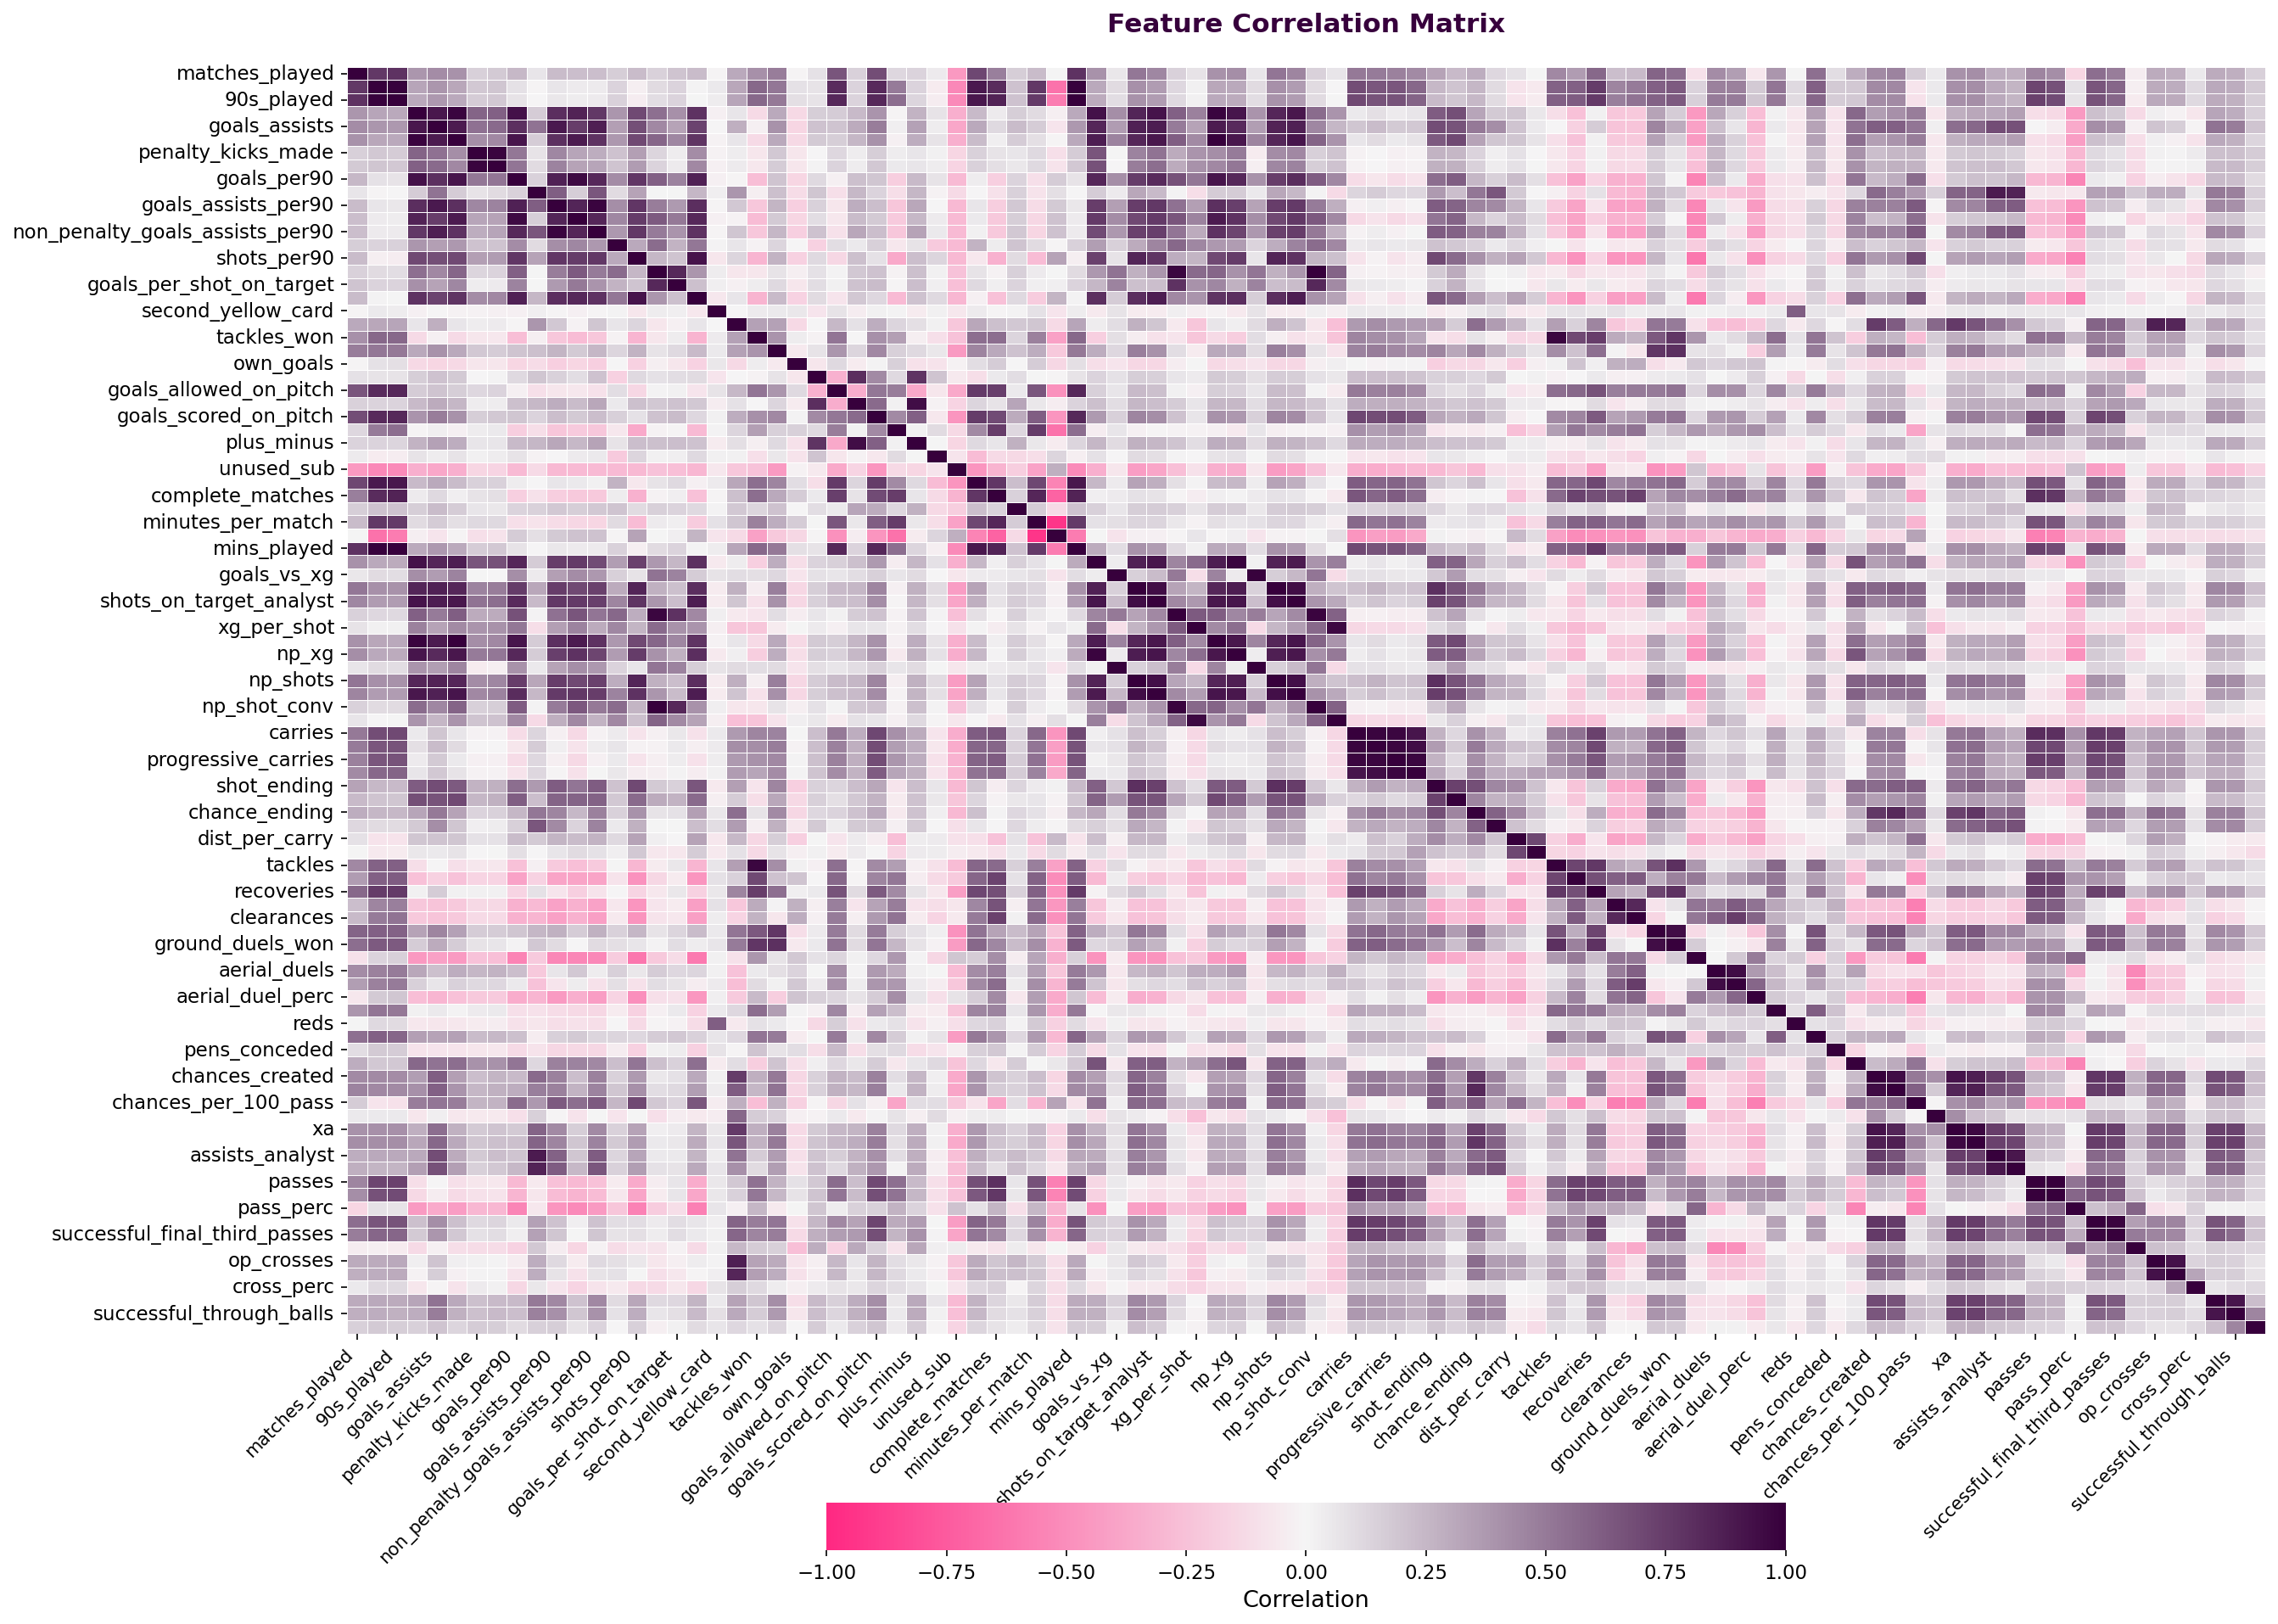

In [ ]:
all_feature_corr = df_numeric.corr()
corr_heatmap_plot(
    corr_df=all_feature_corr,
    title="Feature Correlation Matrix"
)  

In [ ]:
all_feature_corr

,matches_played,starts,90s_played,goals_fbref,goals_assists,non_penalty_goals,penalty_kicks_made,penalty_kicks_attempted,goals_per90,assists_per90,...,pass_perc,total_final_third_passes,successful_final_third_passes,ft_pass_perc,op_crosses,successful_op_crosses,cross_perc,through_balls,successful_through_balls,through_ball_perc
matches_played,1.000000,0.772568,0.794275,0.389433,0.429471,0.401753,0.149716,0.172550,0.243645,0.065272,...,-0.156164,0.547222,0.484913,-0.044333,0.299567,0.284192,0.047609,0.298530,0.287107,0.151121
starts,0.772568,1.000000,0.988671,0.321516,0.384053,0.317007,0.181236,0.192125,0.082813,-0.008997,...,0.082272,0.650250,0.578173,-0.035982,0.298404,0.293899,0.110281,0.306730,0.292504,0.172245
90s_played,0.794275,0.988671,1.000000,0.310072,0.376968,0.307475,0.167910,0.182055,0.072467,-0.006777,...,0.077334,0.658152,0.584215,-0.050000,0.310074,0.304644,0.114675,0.300732,0.280527,0.164050
goals_fbref,0.389433,0.321516,0.310072,1.000000,0.904459,0.978710,0.592219,0.608014,0.922118,0.166687,...,-0.442715,0.214456,0.179430,-0.128175,0.025904,-0.019563,-0.072013,0.320943,0.295249,0.151387
goals_assists,0.429471,0.384053,0.376968,0.904459,1.000000,0.885694,0.533707,0.565178,0.796969,0.525822,...,-0.363318,0.420367,0.384344,-0.028456,0.198025,0.160831,-0.014949,0.529390,0.490611,0.200369
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
successful_op_crosses,0.284192,0.293899,0.304644,-0.019563,0.160831,-0.024781,0.010533,0.013302,-0.090908,0.289525,...,-0.066392,0.453171,0.437955,0.195939,0.926032,1.000000,0.326745,0.161579,0.160743,0.076382
cross_perc,0.047609,0.110281,0.114675,-0.072013,-0.014949,-0.091777,0.040961,0.020737,-0.142919,0.056914,...,0.146742,0.133138,0.122748,0.096762,0.133986,0.326745,1.000000,0.067365,0.097454,0.111716
through_balls,0.298530,0.306730,0.300732,0.320943,0.529390,0.308110,0.213624,0.236740,0.239429,0.503500,...,0.021716,0.661344,0.631666,0.160628,0.158034,0.161579,0.067365,1.000000,0.907760,0.225047
successful_through_balls,0.287107,0.292504,0.280527,0.295249,0.490611,0.278195,0.217128,0.238702,0.220500,0.470016,...,0.022345,0.592920,0.557281,0.133450,0.143723,0.160743,0.097454,0.907760,1.000000,0.453231


#### Near-Duplicate Investigation

In [ ]:
all_feature_corr_abs = all_feature_corr.abs()
upper = all_feature_corr_abs.where(np.triu(np.ones(all_feature_corr_abs.shape), k=1).astype(bool))

near_perfect_dup = upper.stack().reset_index().rename(
    columns={
        "level_0": "Feature 1",
        "level_1": "Feature 2",
        0: "Correlation"
        }
    )

near_perfect_dup["Correlation"] = near_perfect_dup["Correlation"].round(3)
near_perfect_dup = near_perfect_dup[near_perfect_dup["Correlation"] >= 0.99].sort_values("Correlation", ascending=False)

near_perfect_dup

,Feature 1,Feature 2,Correlation
222,90s_played,mins_played,1.000
502,non_penalty_goals,np_goals,1.000
1352,goals_per_shot,np_shot_conv,0.999
2970,shots,np_shots,0.999
3026,shots_on_target_analyst,np_shots_on_target,0.995
4494,passes,successful_passes,0.995
2913,goals_vs_xg,np_goals_vs_xg,0.992


In [ ]:
(df["passes"] == df["successful_passes"]).all()

np.False_

In [ ]:
(df["successful_passes"] / df["passes"]).describe()

count    316.000000
mean       0.817030
std        0.074240
min        0.424242
25%        0.776573
50%        0.833193
75%        0.868300
max        0.954719
dtype: float64

In [ ]:
(df["successful_passes"] > df["passes"]).sum()

np.int64(0)

In [ ]:
df[["Player", "90s_played", "mins_played"]].assign(
    new_column = (df["mins_played"] / df["90s_played"]).round(2)
)

,Player,90s_played,mins_played,new_column
0,Brenden Aaronson,27.2,2465,90.62
5,Tyler Adams,19.7,1778,90.25
8,Amine Adli,12.2,1082,88.69
9,Emmanuel Agbadou,12.2,1101,90.25
11,Ola Aina,17.6,1590,90.34
...,...,...,...,...
487,Evann Guessand,10.2,916,89.80
490,James Ward-Prowse,12.2,1096,89.84
491,Jorgen Strand Larsen,25.6,2316,90.47
493,Marc Guehi,35.0,3150,90.00


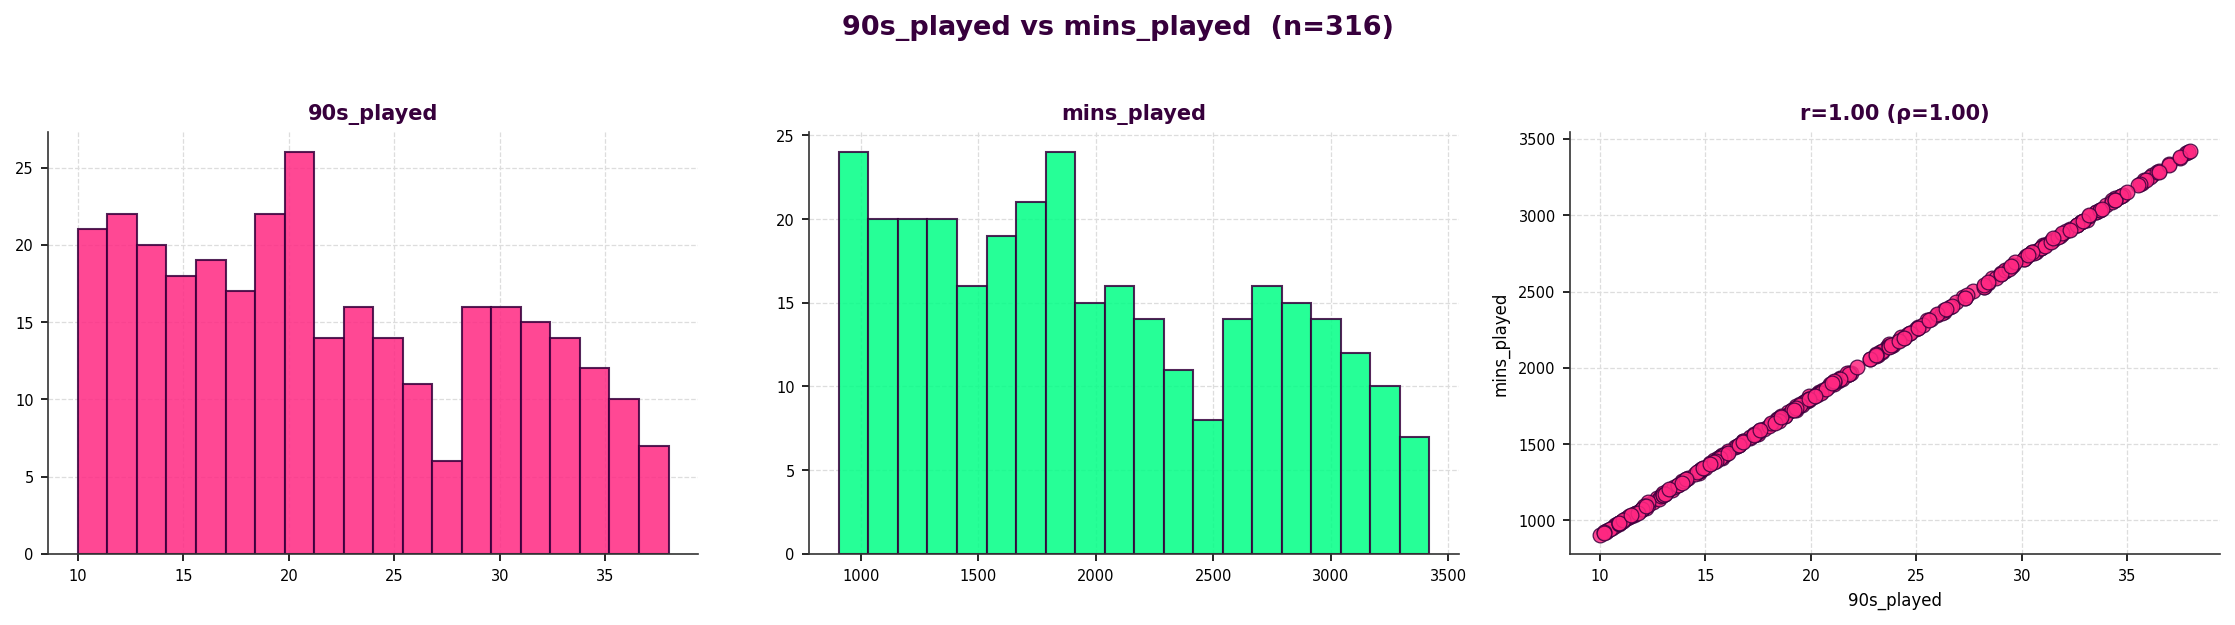

In [ ]:
investigate_correlation_pair(df, ("90s_played", "mins_played"))

In [ ]:
(df["goals_fbref"] / df["90s_played"]).round(3).equals(df["goals_per90"].round(3))

False

In [ ]:

(df["goals_fbref"] / (df["mins_played"] / 90)).round(3).equals(df["goals_per90"].round(3))

False

In [ ]:
diff = (df["goals_fbref"] / df["90s_played"]) - df["goals_per90"]
diff.abs().describe()

count    316.000000
mean       0.001829
std        0.001643
min        0.000000
25%        0.000000
50%        0.001734
75%        0.003228
max        0.005315
dtype: float64

In [ ]:
(df["non_penalty_goals"] == df["np_goals"]).all()

np.True_

In [ ]:
pairs_to_check = [
    ("goals_per_shot", "np_shot_conv"),
    ("shots", "np_shots"),
    ("shots_on_target_analyst", "np_shots_on_target"),
    ("goals_vs_xg", "np_goals_vs_xg"),
]

for total_col, np_col in pairs_to_check:
    diff = df[total_col] - df[np_col]

    print("=" * 70)
    print(f"{total_col}  vs  {np_col}")
    print("=" * 70)
    print(diff.abs().describe())
    print()

    # correlation between the gap and penalty volume.
    # if the value is strongly positive, the gap is explained by penalties
    penalty_corr = diff.corr(df["penalty_kicks_attempted"])
    print(f"Correlation between diff and penalty_kicks_attempted: {penalty_corr:.3f}")

    # players with zero penalties should have ~zero difference
    no_pens = df[df["penalty_kicks_attempted"] == 0]
    zero_pen_diff = (no_pens[total_col] - no_pens[np_col]).abs()
    print(f"Max diff among players with 0 penalty attempts: {zero_pen_diff.max():.4f}")
    print(f"Players with 0 penalty attempts but non-zero diff: {(zero_pen_diff > 0).sum()}")
    print()

goals_per_shot  vs  np_shot_conv
count    316.000000
mean       8.420886
std        7.340540
min        0.000000
25%        2.577500
50%        7.610000
75%       12.370000
max       49.500000
dtype: float64

Correlation between diff and penalty_kicks_attempted: -0.158
Max diff among players with 0 penalty attempts: 49.5000
Players with 0 penalty attempts but non-zero diff: 203

shots  vs  np_shots
count    316.000000
mean       0.281646
std        0.995121
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        9.000000
dtype: float64

Correlation between diff and penalty_kicks_attempted: 1.000
Max diff among players with 0 penalty attempts: 0.0000
Players with 0 penalty attempts but non-zero diff: 0

shots_on_target_analyst  vs  np_shots_on_target
count    316.000000
mean       0.268987
std        0.956409
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        9.000000
dtype: float64

Correlation between diff and 

In [ ]:
df[["goals_per_shot", "np_shot_conv"]].describe()

,goals_per_shot,np_shot_conv
count,316.000000,316.000000
mean,0.084684,8.505570
std,0.073779,7.414246
min,0.000000,0.000000
25%,0.027500,2.605000
50%,0.080000,7.690000
75%,0.130000,12.500000
max,0.500000,50.000000


In [ ]:
(df["goals_per_shot"] * 100).round(3).equals(df["np_shot_conv"].round(3))

False

In [ ]:
diff = (df["goals_per_shot"] * 100) - df["np_shot_conv"]
diff.abs().describe()

count    316.000000
mean       0.202911
std        0.262684
min        0.000000
25%        0.000000
50%        0.140000
75%        0.320000
max        1.860000
dtype: float64

In [ ]:
diff.corr(df["penalty_kicks_attempted"])

no_pens = df[df["penalty_kicks_attempted"] == 0]
no_pens_diff = (no_pens["goals_per_shot"] * 100 - no_pens["np_shot_conv"]).abs()
print(diff.corr(df["penalty_kicks_attempted"])) 
print(no_pens_diff.max())
print((no_pens_diff > 0).sum())

df["goals_per_shot"].head(10) 

-0.4817531163219979
0.6500000000000004
171


0     0.09
5     0.20
8     0.15
9     0.00
11    0.00
12    0.00
13    0.00
16    0.04
20    0.04
21    0.00
Name: goals_per_shot, dtype: float64

#### Near-Duplicate Investigation Findings & Decisions

Correlation analysis identified several feature pairs at ≥0.99 correlation. Before removing any columns from the dataset, each feature was investigated individually to see if the pair represents a true duplicate using exact equality checks, ratio analysis, and mechanism verification against `penalty_kicks_attempted` where relevant.


- `90s_played` vs `mins_played`

    These two features are mathematically equivalent: `90s_played` is a scaled derivative of `mins_played` (`mins_played / 90`).
    For all 116 players, areconstruction check (`mins_played / 90s_played` compared against `goals_per90`) was done and it revealed a maximum discrepancy of ~0.005 . This was cause by the fact that `90s_played` was stored at reduced (1 decimal place) precision rather than any independent measurement. `90s_played` carries no information beyond what `mins_played` already provides.

    Existing `_per90` features (e.g. `goals_per90`) are pre-computed and stored as their own columns, so they are unaffected by dropping `90s_played`. No downstream feature depends on it being recalculated live.

    **Decision:** Drop `90s_played`, retain `mins_played` as the primart playing-time measure.


- `passes` vs `successful_passes`

    These two features correlate at 0.995, initially indicating redundancy. However, an equality check (`(df["passes"] == df["successful_passes"]).all()`) returned `False`, confirming the columns are not identical. When the ratio (`successful_passes / passes`) was examined, it revealed genuine variance across players (mean 82%, standard deviation 7.4%, range 42.4%–95.5%), which is consistent with real pass-completion rates rather than a fixed or derived transformation. 
    A sanity check confirmed no player has more completed passes than attempted (`(successful_passes > passes).sum() == 0`), ruling out a data quality issue.
 
    The near-perfect correlation is because of scale, not substance. Players who attempt more passes overall also tend to complete more too interms of raw numbers. That relationship has nothing to do with accuracy, which is what actually matters here and is captured separetely by `pass_perc`.

    **Decision:** Drop `successful_passes`, retain `pass` (raw_volume) and `pass_perc` separately to capture pass accuracy.


- `non_penalty_goals` vs `np_goals`

    An exact equality check (`(df["non_penalty_goals"] == df["np_goals"]).all()`) returned `True` confirming that every value mataches ecactly across all 316 players, with no rounding or precision ambiguity. These two columns represents the same underlying statistics rather than two conceptually different metrics. `non_penalty_goals` is by FBref and `np_goals` by The Analyst.

    **Decision:** Drop `non_penalty_goals`


- `np_` Pairs — Total vs Non-Penalty Metrics

    Four feature pairs showed near-perfect correlation (0.99–1.0) between a "total" metric and its non-penalty (`np_`) counterpart. Each was investigated individually to determine whether the gap was driven by penalty exclusion, a unit/scale difference, or a data artifact, rather than assuming redundancy from correlation strength alone.

    - **`shots` vs `np_shots`**

        The difference between the two columns correlated perfectly with `penalty_kicks_attempted` (r = 1.000), and every player with zero penalty attempts showed exactly zero difference between the two columns. This confirms the gap is fully explained by penalty shot volume.

        **Decision:** Retain `shots` (standard, widely-reported shot volume metric); drop `np_shots`.

    - **`shots_on_target_analyst` vs `np_shots_on_target`**

        Same pattern, difference correlated strongly with `penalty_kicks_attempted` (r = 0.994), with zero difference among all zero-penalty players. Confirmed as a clean penalty-inclusion/exclusion pair.

        **Decision:** Retain `shots_on_target_analyst` (standard shots-on-target metric); drop `np_shots_on_target`.

    - **`goals_vs_xg` vs `np_goals_vs_xg`**

        The correlation between the difference and `penalty_kicks_attempted` was weaker this time (r = 0.251), but the zero-penalty subset showed exactly zero difference for all players. This confirms that penalties are still the cause and the weaker correlation just shows that the *size* of the gap depends on the penalty's xG and whether it went in, not simply how many a player took.

        There's also a football reason to prefer the non-penalty version here, beyond the data. This metric is meant to capture finishing skill. The penalties are high-xG, high-conversion, low-variance events that say more about being the team's designated taker than about the finishing ability in open play. 

        **Decision:** Retain `np_goals_vs_xg` (isolates open-play finishing skill); drop `goals_vs_xg`.


    - **`goals_per_shot` vs `np_shot_conv`**

        Initially this looked like it would follow the same penalty-driven pattern, but investigation rules this out. The summary stats showed that both features are on different scale (`np_shot_conv` is on a 0–100 scale, `goals_per_shot` is 0–1) roughly a 100x difference. After adjusting for scale there was still a residual gap (averaging 0.20, up to 1.86), so the penalty theory got tested properly: the correlation between that gap and `penalty_kicks_attempted` came back weak and *negative* (-0.48), and 171 of 316 players who never took a penalty still showed a nonzero gap (up to 0.65). That rules penalties out as the cause. The more likely explanation is simpler — `goals_per_shot` is just stored with less decimal precision, and multiplying it by 100 to compare against `np_shot_conv` stretches that rounding error into something that looks bigger than it actually is.

        **Decision:** Retain `np_shot_conv` (non-penalty, higher-precision conversion rate); drop `goals_per_shot`.


**Summary**

| Pair | Mechanism confirmed | Retained | Dropped |
|---|---|---|---|
| `90s_played` / `mins_played` | Derived (÷90), precision artifact | `mins_played` | `90s_played` |
| `passes` / `successful_passes` | Scale-driven correlation, not a duplicate | `passes`, `pass_perc` (accuracy signal) | `successful_passes` |
| `non_penalty_goals` / `np_goals` | Exact duplicate (cross-source) | `np_goals` | `non_penalty_goals` |
| `shots` / `np_shots` | Penalty exclusion (r=1.000, zero-penalty diff = 0) | `shots` | `np_shots` |
| `shots_on_target_analyst` / `np_shots_on_target` | Penalty exclusion (r=0.994, zero-penalty diff = 0) | `shots_on_target_analyst` | `np_shots_on_target` |
| `goals_vs_xg` / `np_goals_vs_xg` | Penalty exclusion; non-penalty version isolates finishing skill | `np_goals_vs_xg` | `goals_vs_xg` |
| `goals_per_shot` / `np_shot_conv` | Scale (×100) + rounding precision, not penalties | `np_shot_conv` | `goals_per_shot` |

In [ ]:
cols_to_drop = ["np_shots", "np_shots_on_target", "goals_vs_xg", "goals_per_shot", "90s_played", "successful_passes", "non_penalty_goals", "90s_played"]

df = df.drop(columns=cols_to_drop)
df_numeric = df.select_dtypes(include="number")


In [ ]:
df_numeric.shape

(316, 89)

In [ ]:
all_feature_corr = df_numeric.corr()

#### Strong Correlation Analysis (≥0.75)

In [ ]:
upper = all_feature_corr.where(np.triu(np.ones(all_feature_corr.shape), k=1).astype(bool))

strong_corr = upper.stack().reset_index().rename(
    columns={
        "level_0": "Feature 1",
        "level_1": "Feature 2",
        0: "Correlation"
    }
)

strong_corr["Correlation"] = strong_corr["Correlation"].round(3)
strong_corr["Abs Correlation"] = strong_corr["Correlation"].abs()


In [ ]:
strong_corr = strong_corr.loc[strong_corr["Abs Correlation"] >= 0.75].sort_values(
    by="Abs Correlation", 
    ascending=False
    )

In [ ]:
for _, row in strong_corr.iterrows():
    print(
        f"{row['Feature 1']} ↔ {row['Feature 2']} "
        f"({row['Correlation']:.3f})"
    )

starts ↔ mins_played (0.989)
carries ↔ carry_distance (0.981)
goals_assists_per90 ↔ non_penalty_goals_assists_per90 (0.981)
total_final_third_passes ↔ successful_final_third_passes (0.981)
xg ↔ np_xg (0.980)
goals_fbref ↔ np_goals (0.979)
shot_conv ↔ np_shot_conv (0.978)
penalty_kicks_made ↔ penalty_kicks_attempted (0.978)
progressive_carries ↔ progressive_distance (0.975)
tackles_won ↔ tackles (0.972)
carry_distance ↔ progressive_carries (0.971)
carries ↔ progressive_carries (0.969)
xg_per_shot ↔ np_xg_per_shot (0.967)
xa ↔ op_xa (0.962)
goals_per90 ↔ non_penalty_goals_per90 (0.960)
chances_created ↔ op_chances_created (0.946)
ground_duels ↔ ground_duels_won (0.945)
carry_distance ↔ progressive_distance (0.945)
aerial_duels ↔ aerial_duels_won (0.945)
plus_minus_per90 ↔ plus_minus (0.941)
shots ↔ shots_on_target_analyst (0.939)
minutes_per_match ↔ sub_appearances (-0.932)
op_crosses ↔ successful_op_crosses (0.926)
goals_fbref ↔ xg (0.925)
goals_fbref ↔ goals_per90 (0.922)
chances_creat

In [ ]:
np_strong_corr = strong_corr.loc[
    (
        strong_corr["Feature 1"].str.contains("np|non_penalty") | (strong_corr["Feature 2"].str.contains("np|non_penalty"))
    ),
    ["Feature 1", "Feature 2"]
    ]

In [ ]:
np_strong_corr["Pearson r"] = np_strong_corr.apply(
    lambda row: df[row["Feature 1"]].corr(df[row["Feature 2"]], method="pearson").round(3),
    axis=1
)

In [ ]:
np_strong_corr["Spearman ρ"] = np_strong_corr.apply(
    lambda row: df[row["Feature 1"]].corr(df[row["Feature 2"]], method="spearman").round(3),
    axis=1
)

In [ ]:
np_strong_corr["Mean Difference"] = np_strong_corr.apply(
    lambda row: (df[row["Feature 1"]] - df[row["Feature 2"]]).mean().round(3),
    axis=1
)

In [ ]:
np_strong_corr["Median Difference"] = np_strong_corr.apply(
    lambda row: (df[row["Feature 1"]] - df[row["Feature 2"]]).median().round(3),
    axis=1
)

In [ ]:
np_strong_corr["Mean Absolute Difference"] = np_strong_corr.apply(
    lambda row: (df[row["Feature 1"]] - df[row["Feature 2"]]).abs().mean().round(3),
    axis=1
)

In [ ]:
np_strong_corr["Median Absolute Difference"] = np_strong_corr.apply(
    lambda row: (df[row["Feature 1"]] - df[row["Feature 2"]]).abs().median().round(3),
    axis=1
)

In [ ]:
np_strong_corr["Max Absolute Difference"] = np_strong_corr.apply(
    lambda row: (df[row["Feature 1"]] - df[row["Feature 2"]]).abs().max().round(3),
    axis=1
)

In [ ]:
np_strong_corr["Players Affected"] = np_strong_corr.apply(
    lambda row: (
        (df[row["Feature 1"]] - df[row["Feature 2"]]).abs() > 0.001
    ).sum(),
    axis=1
)

np_strong_corr["Percentage Affected"] = (
    np_strong_corr["Players Affected"]
    / len(df)
    * 100
).round(2)

In [ ]:
np_strong_corr

,Feature 1,Feature 2,Pearson r,Spearman ρ,Mean Difference,Median Difference,Mean Absolute Difference,Median Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
677,goals_assists_per90,non_penalty_goals_assists_per90,0.981,0.988,0.007,0.000,0.012,0.000,0.23,39,12.34
2436,xg,np_xg,0.980,0.993,0.222,0.000,0.222,0.000,7.09,36,11.39
211,goals_fbref,np_goals,0.979,0.993,0.234,0.000,0.234,0.000,8.00,33,10.44
2594,shot_conv,np_shot_conv,0.978,0.974,0.427,0.000,0.430,0.000,16.67,36,11.39
2645,xg_per_shot,np_xg_per_shot,0.967,0.968,0.004,0.000,0.004,0.000,0.12,36,11.39
515,goals_per90,non_penalty_goals_per90,0.960,0.972,0.011,0.000,0.013,0.000,0.37,39,12.34
545,goals_per90,np_goals,0.912,0.955,-2.591,-1.785,2.592,1.785,23.18,239,75.63
2541,shots_on_target_analyst,np_xg,0.910,0.888,6.358,4.630,6.394,4.630,36.76,312,98.73
212,goals_fbref,np_xg,0.910,0.825,0.098,-0.130,1.102,0.720,8.51,312,98.73
2540,shots_on_target_analyst,np_goals,0.904,0.852,6.494,5.000,6.494,5.000,35.00,290,91.77


In [ ]:
np_strong_corr[
    (np_strong_corr["Pearson r"] >= 0.95) &
    (np_strong_corr["Spearman ρ"] >= 0.95) &
    (np_strong_corr["Median Absolute Difference"] == 0)
]

,Feature 1,Feature 2,Pearson r,Spearman ρ,Mean Difference,Median Difference,Mean Absolute Difference,Median Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
677,goals_assists_per90,non_penalty_goals_assists_per90,0.981,0.988,0.007,0.0,0.012,0.0,0.23,39,12.34
2436,xg,np_xg,0.980,0.993,0.222,0.0,0.222,0.0,7.09,36,11.39
211,goals_fbref,np_goals,0.979,0.993,0.234,0.0,0.234,0.0,8.00,33,10.44
2594,shot_conv,np_shot_conv,0.978,0.974,0.427,0.0,0.430,0.0,16.67,36,11.39
2645,xg_per_shot,np_xg_per_shot,0.967,0.968,0.004,0.0,0.004,0.0,0.12,36,11.39
515,goals_per90,non_penalty_goals_per90,0.960,0.972,0.011,0.0,0.013,0.0,0.37,39,12.34


In [ ]:
redundant_candidates = np_strong_corr[
    (np_strong_corr["Pearson r"] >= 0.95) &
    (np_strong_corr["Spearman ρ"] >= 0.95) &
    (np_strong_corr["Percentage Affected"] <= 25)
].copy()

In [ ]:
redundant_candidates

,Feature 1,Feature 2,Pearson r,Spearman ρ,Mean Difference,Median Difference,Mean Absolute Difference,Median Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
677,goals_assists_per90,non_penalty_goals_assists_per90,0.981,0.988,0.007,0.0,0.012,0.0,0.23,39,12.34
2436,xg,np_xg,0.980,0.993,0.222,0.0,0.222,0.0,7.09,36,11.39
211,goals_fbref,np_goals,0.979,0.993,0.234,0.0,0.234,0.0,8.00,33,10.44
2594,shot_conv,np_shot_conv,0.978,0.974,0.427,0.0,0.430,0.0,16.67,36,11.39
2645,xg_per_shot,np_xg_per_shot,0.967,0.968,0.004,0.0,0.004,0.0,0.12,36,11.39
515,goals_per90,non_penalty_goals_per90,0.960,0.972,0.011,0.0,0.013,0.0,0.37,39,12.34


In [ ]:
def diff_distribution_plot(
        df:pd.DataFrame,
        feature_pair:tuple[str, str],
        title:str,
        bins:int|str = "auto",
        figsize:tuple[int, int] = (12, 8)
):
    feature_1, feature_2 = feature_pair

    analysis_df = df[[feature_1, feature_2]].copy()

    analysis_df["diff"] = (
        analysis_df[feature_1] - analysis_df[feature_2]
        )

    analysis_df["abs_diff"] = analysis_df["diff"].abs()

    fig, ax = plt.subplots(figsize=figsize)
    
    sns.histplot(
            data=analysis_df,
            x="diff",
            bins=bins,
            color=ACCENT,
            edgecolor=PRIMARY,
            alpha=0.80,
            ax=ax,
        )
    

    ax.axvline(0, linestyle="--", color=SECONDARY, linewidth=0.6)
    
    style_plot(
            ax=ax,
            title=title
        )

    ax.set_xlabel("Difference")
    ax.set_ylabel("Number of Players")
    
    plt.tight_layout()
    plt.show()


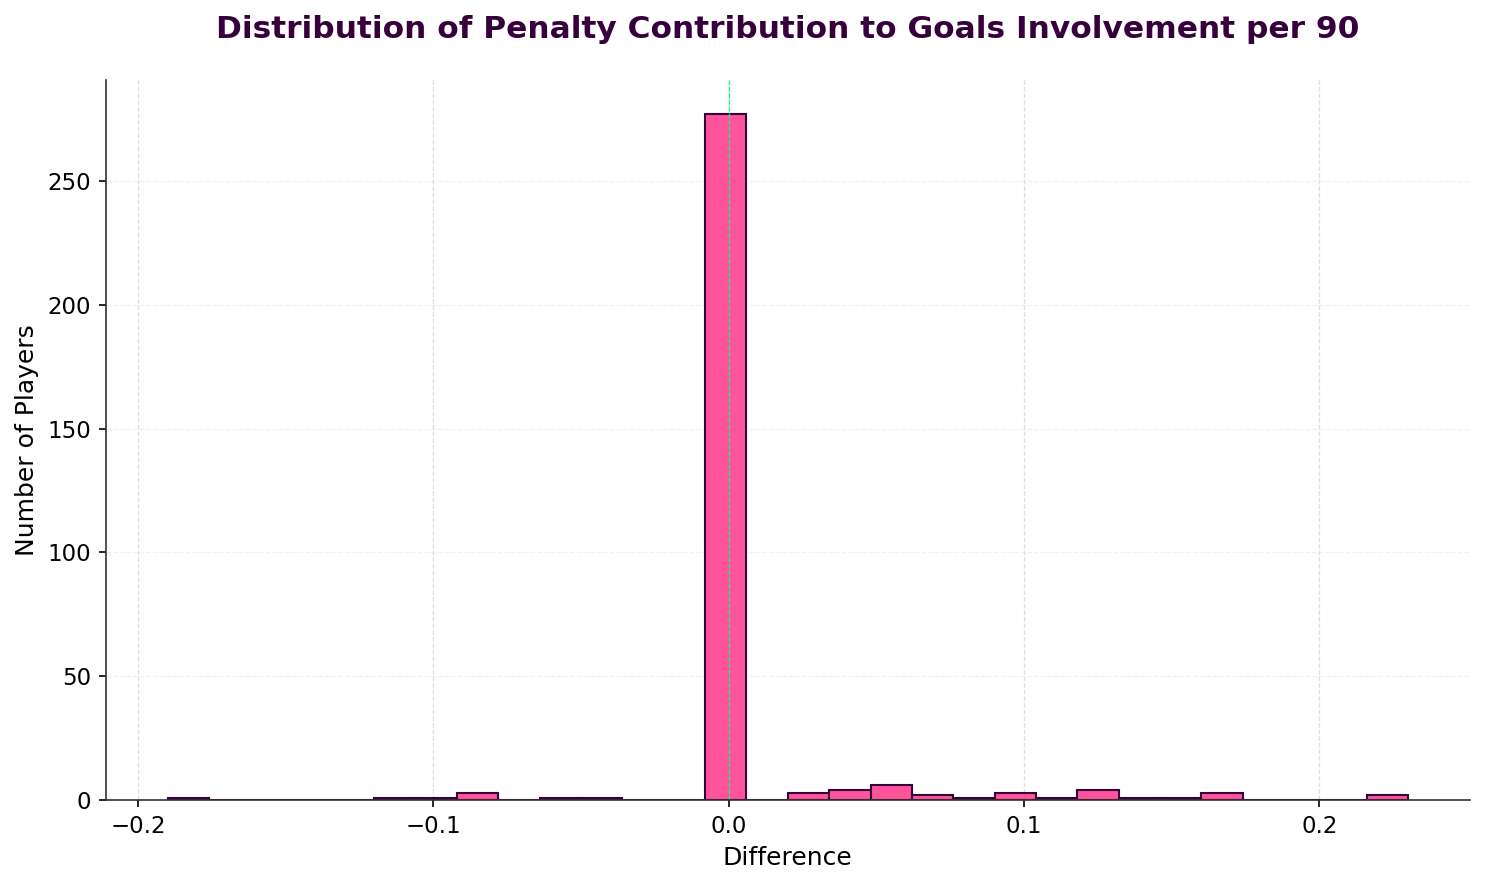

In [ ]:
diff_distribution_plot(
    df, 
    ("goals_assists_per90", "non_penalty_goals_assists_per90"), 
    "Distribution of Penalty Contribution to Goals Involvement per 90", 
    figsize=(10, 6),
    bins=30
    )

- **"goals_assists_per90"** vs **"non_penalty_goals_assists_per90"**

    The distribution is heavily concentrated at zero, indicating that goals_assists_per90 and non_penalty_goals_assists_per90 produce identical values for most players. The fact that the differences are limited to a relatively small subset indicates that the two features capture informations that is essentenially overlapping, with the remaining differences likely reflecting penalty contributions.

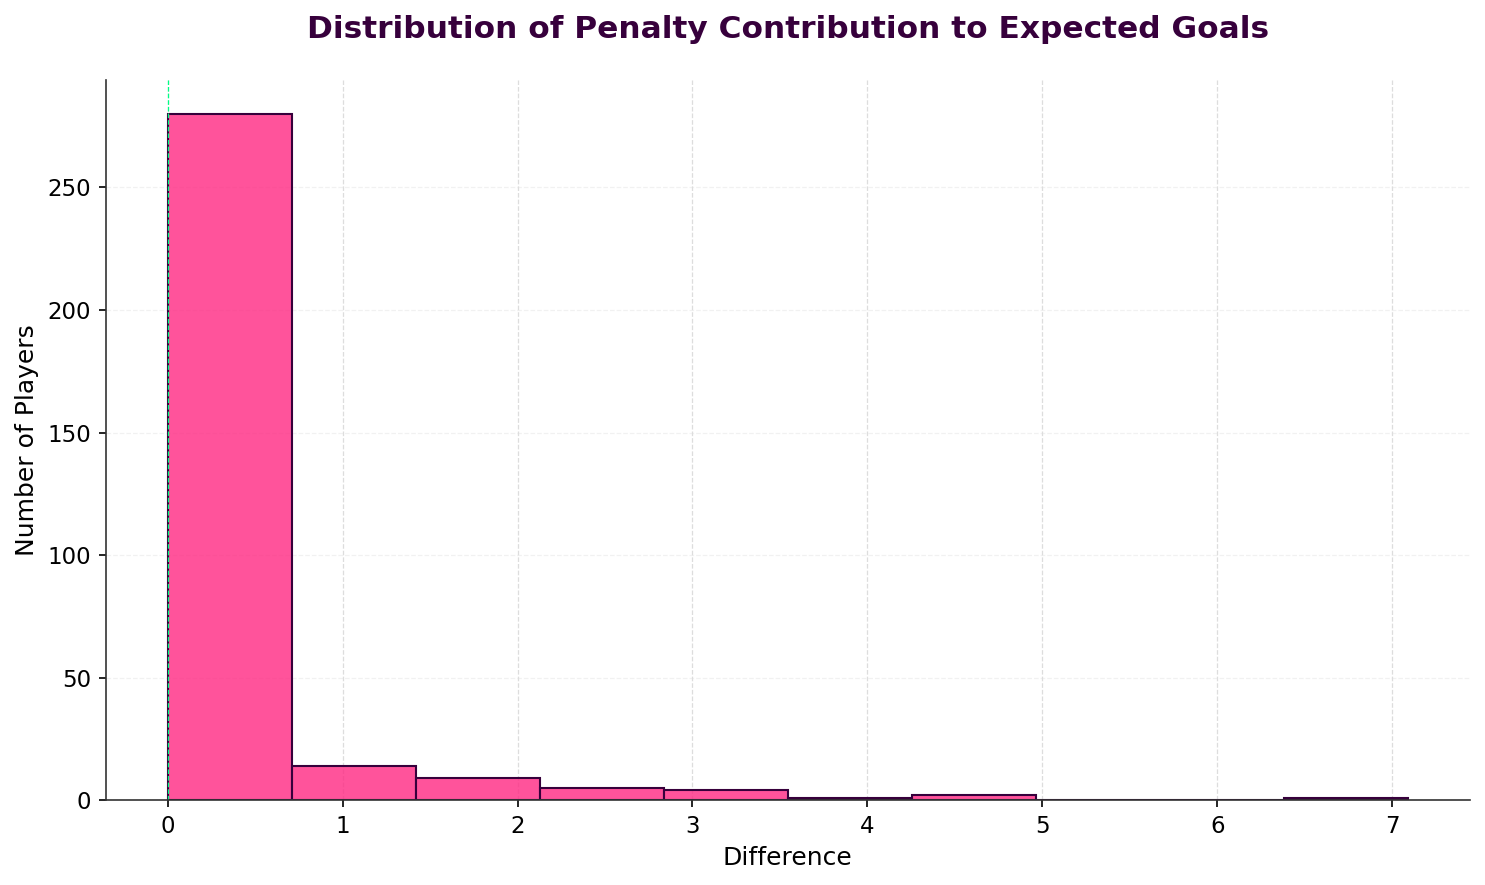

In [ ]:
diff_distribution_plot(
    df, 
    ("xg", "np_xg"), 
    "Distribution of Penalty Contribution to Expected Goals", 
    figsize=(10, 6),
    bins=10
    )

The difference distribution is heavily concentrated at zero, indicating that xg and np_xg are identical for most players. Only a small subset have non-zero differences, representing the contribution of penalty xG.

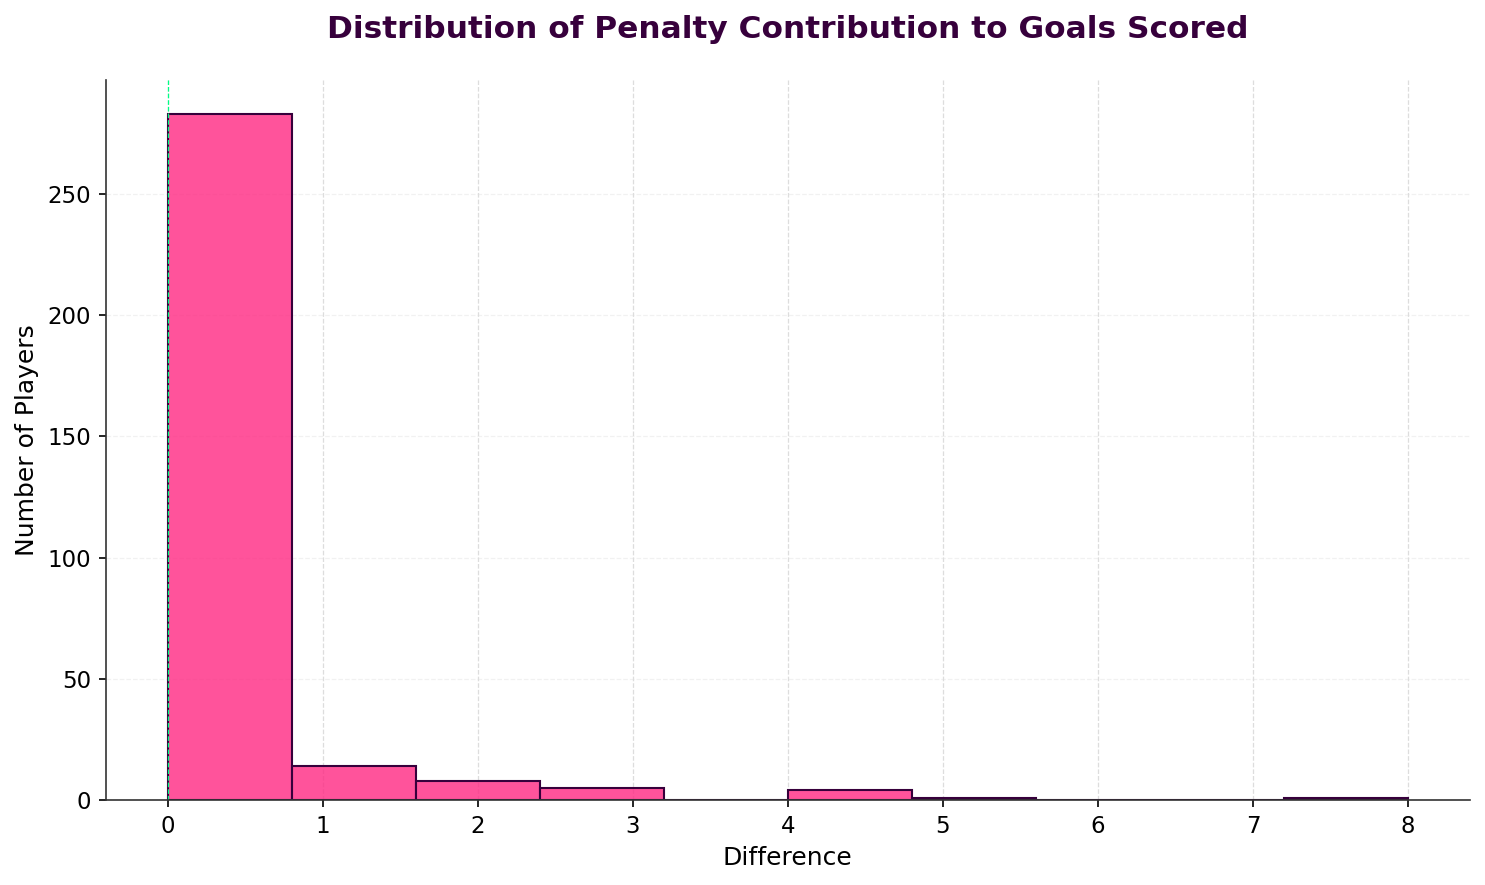

In [ ]:
diff_distribution_plot(
    df, 
    ("goals_fbref", "np_goals"), 
    "Distribution of Penalty Contribution to Goals Scored", 
    figsize=(10, 6),
    bins=10
    )

The difference between `goals_fbref` and `np_goals` is heavily concentrated at zero, indicating that the two features are identical for most players. Only a small proportion of players show a non-zero difference, reflecting the contribution of penalty goals.

This is consistent with the strong correlation between the features (**Pearson r = 0.979**, **Spearman ρ = 0.993**) and the **median absolute difference of 0.000**. Overall, the two features capture largely overlapping information, making them a strong redundancy candidate.

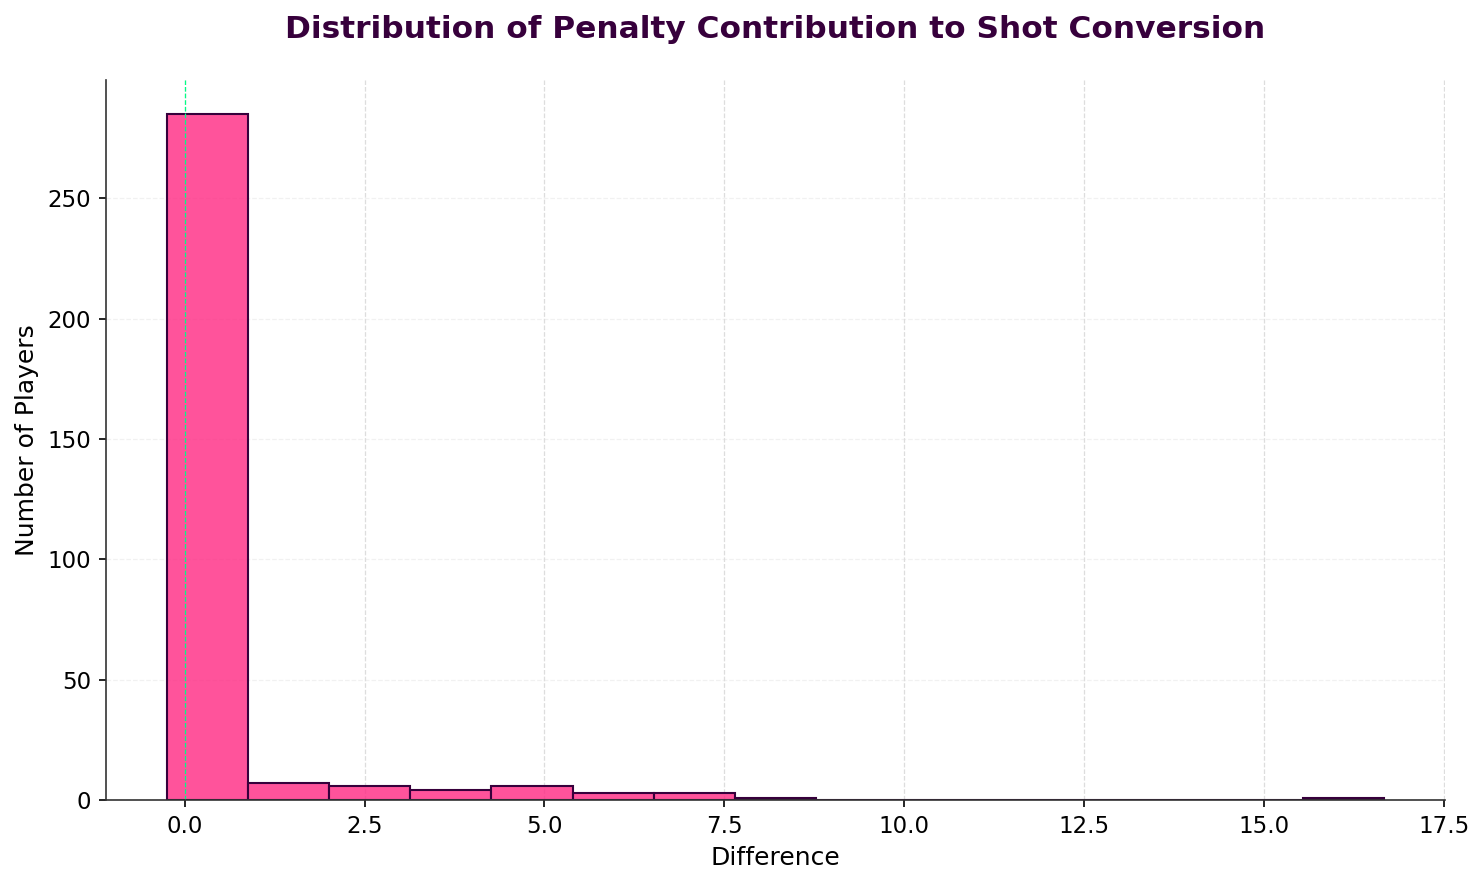

In [ ]:
diff_distribution_plot(
    df, 
    ("shot_conv", "np_shot_conv"), 
    "Distribution of Penalty Contribution to Shot Conversion", 
    figsize=(10, 6),
    bins=15
    )

The two shot-conversion measures are identical for most players, indicating substantial overlap. However, the affected players can experience relatively large differences, with the maximum difference reaching **16.67 percentage points**. Therefore, the features are strong redundancy candidates, but the impact of penalty shots should be considered before selecting one.

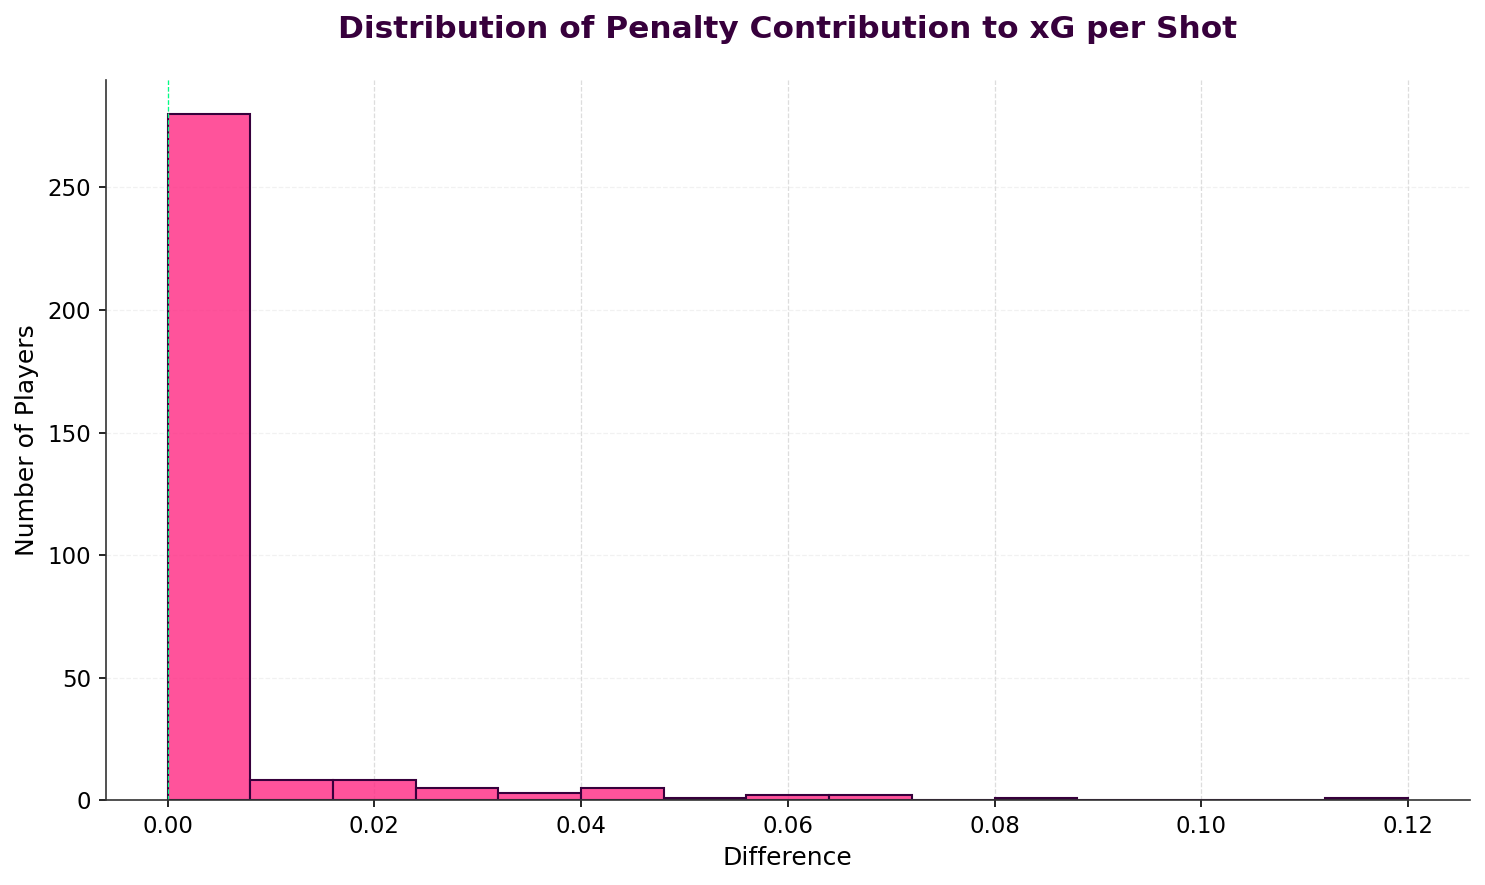

In [ ]:
diff_distribution_plot(
    df, 
    ("xg_per_shot", "np_xg_per_shot"), 
    "Distribution of Penalty Contribution to xG per Shot", 
    figsize=(10, 6),
    bins=15
    )

The difference between `xg_per_shot` and `np_xg_per_shot` is heavily concentrated at zero, indicating that the two features are identical for most players. Only **11.39%** of players are affected, and the median absolute difference is **0.000**.

This is consistent with the very high correlation between the features (**Pearson r = 0.967**, **Spearman ρ = 0.968**). Although some players show differences, the overall evidence indicates substantial overlap between the two features, making them a strong redundancy candidate. The differences should therefore be considered in the context of penalty contributions before selecting one feature.

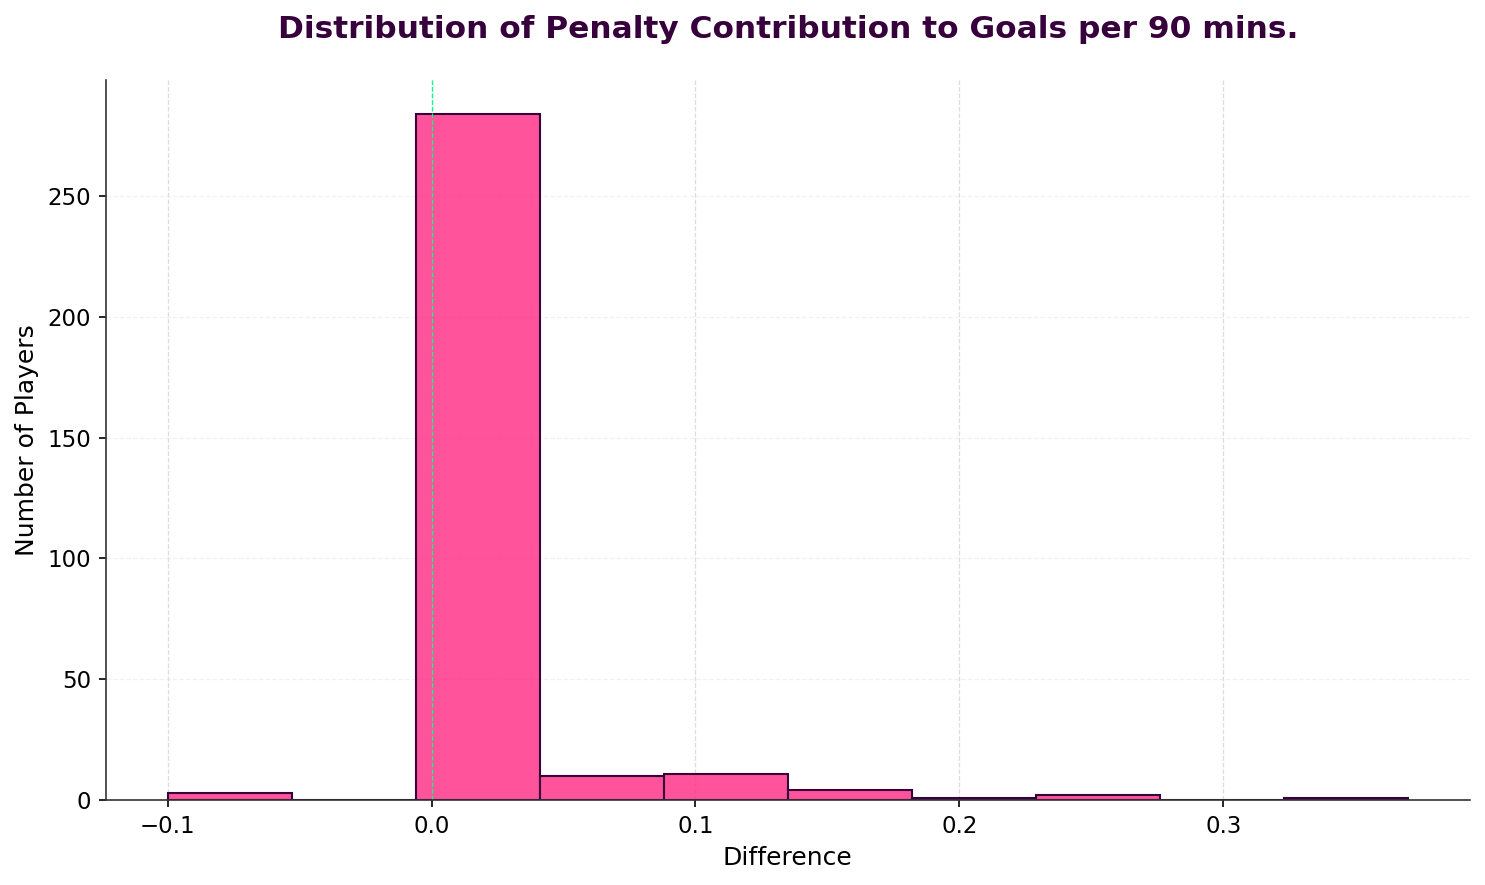

In [ ]:
diff_distribution_plot(
    df, 
    ("goals_per90", "non_penalty_goals_per90"), 
    "Distribution of Penalty Contribution to Goals per 90 mins.", 
    figsize=(10, 6),
    bins=10
    )

In [ ]:
goals_per_90_diff = df[["goals_per90", "non_penalty_goals_per90"]].copy()

goals_per_90_diff["diff"] = goals_per_90_diff["goals_per90"] - goals_per_90_diff["non_penalty_goals_per90"]

goals_per_90_diff.loc[goals_per_90_diff["diff"] < 0]

,goals_per90,non_penalty_goals_per90,diff
487,0.1,0.20,-0.10
490,0.0,0.08,-0.08
494,0.0,0.09,-0.09


In [ ]:
df.loc[
    goals_per_90_diff["diff"] < 0,
    [
        "Player",
        "goals_per90",
        "non_penalty_goals_per90",
        "goals_fbref",
        "np_goals",
        "mins_played",
        "penalty_kicks_made",
        "penalty_kicks_attempted"
    ]
]

,Player,goals_per90,non_penalty_goals_per90,goals_fbref,np_goals,mins_played,penalty_kicks_made,penalty_kicks_attempted
487,Evann Guessand,0.1,0.20,1.0,1,916,0.0,0.0
490,James Ward-Prowse,0.0,0.08,0.0,0,1096,0.0,0.0
494,Oscar Bobb,0.0,0.09,0.0,0,1037,0.0,0.0


The difference distribution is heavily concentrated around zero, indicating substantial overlap between `goals_per90` and `non_penalty_goals_per90`. Only **12.34%** of players are affected, while the median absolute difference is **0.000**.

This is consistent with the strong correlation between the features (**Pearson r = 0.960**, **Spearman ρ = 0.972**), making them a strong redundancy candidate. Three players show negative differences that appear inconsistent with the expected relationship between the metrics; these observations are noted as potential data inconsistencies but do not alter the overall redundancy assessment.

In [ ]:
np_quick_screening = np_strong_corr.merge(redundant_candidates[["Feature 1", "Feature 2"]], on=["Feature 1", "Feature 2"], how="left",  indicator=True)
np_quick_screening = np_quick_screening[np_quick_screening["_merge"] == "left_only"].drop(columns="_merge")


In [ ]:
np_quick_screening

,Feature 1,Feature 2,Pearson r,Spearman ρ,Mean Difference,Median Difference,Mean Absolute Difference,Median Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
6,goals_per90,np_goals,0.912,0.955,-2.591,-1.785,2.592,1.785,23.18,239,75.63
7,shots_on_target_analyst,np_xg,0.910,0.888,6.358,4.630,6.394,4.630,36.76,312,98.73
8,goals_fbref,np_xg,0.910,0.825,0.098,-0.130,1.102,0.720,8.51,312,98.73
9,shots_on_target_analyst,np_goals,0.904,0.852,6.494,5.000,6.494,5.000,35.00,290,91.77
10,np_goals,np_xg,0.902,0.825,-0.136,-0.195,1.044,0.750,6.49,311,98.42
11,non_penalty_goals_per90,np_goals,0.887,0.944,-2.603,-1.815,2.604,1.815,23.27,240,75.95
12,goals_assists,np_goals,0.886,0.868,2.231,2.000,2.231,2.000,25.00,238,75.32
13,xg,np_goals,0.879,0.822,0.358,0.225,1.164,0.750,6.58,312,98.73
14,shots,np_xg,0.875,0.894,24.374,19.785,24.374,19.785,103.76,313,99.05
15,goals_assists,non_penalty_goals_assists_per90,0.869,0.922,4.741,3.720,4.741,3.720,34.02,283,89.56


In [79]:
np_quick_screening.describe()

,Pearson r,Spearman ρ,Mean Difference,Median Difference,Mean Absolute Difference,Median Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
count,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000
mean,0.833387,0.832613,1.020323,0.912581,4.052839,3.044032,24.962258,285.935484,90.485484
std,0.050735,0.057006,7.093766,5.658915,5.886307,4.835807,25.196349,30.992403,9.807039
min,0.754000,0.748000,-9.096000,-7.400000,0.090000,0.070000,0.610000,233.000000,73.730000
25%,0.793000,0.793000,-2.506500,-1.575000,1.113500,0.792500,6.535000,261.000000,82.595000
50%,0.833000,0.822000,-0.204000,-0.195000,2.531000,1.640000,22.930000,296.000000,93.670000
75%,0.877000,0.860000,2.163000,1.545000,2.899000,1.920000,26.145000,313.000000,99.050000
max,0.912000,0.955000,24.509000,20.000000,24.509000,20.000000,103.760000,315.000000,99.680000


In [ ]:
np_quick_screening.loc[
    (np_quick_screening["Pearson r"] >= 0.90) 
    & (np_quick_screening["Spearman ρ"] >= 0.90)
    ]

,Feature 1,Feature 2,Pearson r,Spearman ρ,Mean Difference,Median Difference,Mean Absolute Difference,Median Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
6,goals_per90,np_goals,0.912,0.955,-2.591,-1.785,2.592,1.785,23.18,239,75.63


In [85]:
np_quick_screening

,Feature 1,Feature 2,Pearson r,Spearman ρ,Mean Difference,Median Difference,Mean Absolute Difference,Median Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
6,goals_per90,np_goals,0.912,0.955,-2.591,-1.785,2.592,1.785,23.18,239,75.63
7,shots_on_target_analyst,np_xg,0.910,0.888,6.358,4.630,6.394,4.630,36.76,312,98.73
8,goals_fbref,np_xg,0.910,0.825,0.098,-0.130,1.102,0.720,8.51,312,98.73
9,shots_on_target_analyst,np_goals,0.904,0.852,6.494,5.000,6.494,5.000,35.00,290,91.77
10,np_goals,np_xg,0.902,0.825,-0.136,-0.195,1.044,0.750,6.49,311,98.42
11,non_penalty_goals_per90,np_goals,0.887,0.944,-2.603,-1.815,2.604,1.815,23.27,240,75.95
12,goals_assists,np_goals,0.886,0.868,2.231,2.000,2.231,2.000,25.00,238,75.32
13,xg,np_goals,0.879,0.822,0.358,0.225,1.164,0.750,6.58,312,98.73
14,shots,np_xg,0.875,0.894,24.374,19.785,24.374,19.785,103.76,313,99.05
15,goals_assists,non_penalty_goals_assists_per90,0.869,0.922,4.741,3.720,4.741,3.720,34.02,283,89.56


The remaining 31 non-penalty pairs were reviewed using their correlations, percentage of players affected, and difference measures. While some pairs showed strong correlations, the differences between the features were much larger and affected a large proportion of players compared with the six pairs investigated earlier. This suggests that these features are related, but they are not simply duplicate versions of the same metric. Therefore, no additional strong redundancy candidates were identified, and the six previously investigated pairs remain the main non-penalty pairs requiring a feature selection decision.

In [86]:
strong_corr

,Feature 1,Feature 2,Correlation,Abs Correlation
119,starts,mins_played,0.989,0.989
2926,carries,carry_distance,0.981,0.981
677,goals_assists_per90,non_penalty_goals_assists_per90,0.981,0.981
3880,total_final_third_passes,successful_final_third_passes,0.981,0.981
2436,xg,np_xg,0.980,0.980
...,...,...,...,...
3771,op_chances_created,total_final_third_passes,0.753,0.753
541,goals_per90,shots,0.751,0.751
3750,chances_created,assists_analyst,0.751,0.751
3455,clearances,aerial_duels_won,0.750,0.750


In [87]:
np_strong_corr

,Feature 1,Feature 2,Pearson r,Spearman ρ,Mean Difference,Median Difference,Mean Absolute Difference,Median Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
677,goals_assists_per90,non_penalty_goals_assists_per90,0.981,0.988,0.007,0.000,0.012,0.000,0.23,39,12.34
2436,xg,np_xg,0.980,0.993,0.222,0.000,0.222,0.000,7.09,36,11.39
211,goals_fbref,np_goals,0.979,0.993,0.234,0.000,0.234,0.000,8.00,33,10.44
2594,shot_conv,np_shot_conv,0.978,0.974,0.427,0.000,0.430,0.000,16.67,36,11.39
2645,xg_per_shot,np_xg_per_shot,0.967,0.968,0.004,0.000,0.004,0.000,0.12,36,11.39
515,goals_per90,non_penalty_goals_per90,0.960,0.972,0.011,0.000,0.013,0.000,0.37,39,12.34
545,goals_per90,np_goals,0.912,0.955,-2.591,-1.785,2.592,1.785,23.18,239,75.63
2541,shots_on_target_analyst,np_xg,0.910,0.888,6.358,4.630,6.394,4.630,36.76,312,98.73
212,goals_fbref,np_xg,0.910,0.825,0.098,-0.130,1.102,0.720,8.51,312,98.73
2540,shots_on_target_analyst,np_goals,0.904,0.852,6.494,5.000,6.494,5.000,35.00,290,91.77


In [101]:
remaining_strong_corr = strong_corr.merge(
    np_strong_corr[["Feature 1", "Feature 2"]], 
    on=["Feature 1", "Feature 2"],
    how="left",
    indicator=True
    )

remaining_strong_corr = remaining_strong_corr[remaining_strong_corr["_merge"] == "left_only"].drop(columns="_merge")

In [102]:
remaining_strong_corr

,Feature 1,Feature 2,Correlation,Abs Correlation
0,starts,mins_played,0.989,0.989
1,carries,carry_distance,0.981,0.981
3,total_final_third_passes,successful_final_third_passes,0.981,0.981
7,penalty_kicks_made,penalty_kicks_attempted,0.978,0.978
8,progressive_carries,progressive_distance,0.975,0.975
...,...,...,...,...
134,op_chances_created,total_final_third_passes,0.753,0.753
135,goals_per90,shots,0.751,0.751
136,chances_created,assists_analyst,0.751,0.751
137,clearances,aerial_duels_won,0.750,0.750


In [103]:
conditions = [
    remaining_strong_corr["Abs Correlation"] >= 0.9,
    (remaining_strong_corr["Abs Correlation"] >= 0.85) & (remaining_strong_corr["Abs Correlation"] < 0.9),
    (remaining_strong_corr["Abs Correlation"] >= 0.75) & (remaining_strong_corr["Abs Correlation"] < 0.85)
]

choices = [
        "Very Strong",
        "Strong",
        "Moderate Strong"
]

remaining_strong_corr["corr_strength"] = np.select(conditions, choices, default="Weak")

In [122]:
remaining_strong_corr["corr_strength"].value_counts(normalize=True).round(2)

corr_strength
Moderate Strong    0.59
Very Strong        0.27
Strong             0.14
Name: proportion, dtype: float64

In [105]:
remaining_strong_corr["Pearson r"] = remaining_strong_corr.apply(
    lambda row: (df[row["Feature 1"]].corr(df[row["Feature 2"]], method="pearson").round(3)),
    axis=1
)

In [107]:
remaining_strong_corr["Spearman p"] = remaining_strong_corr.apply(
    lambda row: (df[row["Feature 1"]].corr(df[row["Feature 2"]], method="spearman").round(3)),
    axis=1
)

In [112]:
(remaining_strong_corr["Pearson r"] - remaining_strong_corr["Spearman p"]).describe().round(3)

count    102.000
mean      -0.000
std        0.033
min       -0.080
25%       -0.022
50%       -0.001
75%        0.017
max        0.090
dtype: float64

In [123]:
remaining_strong_corr["Median Aboslute Difference"] = remaining_strong_corr.apply(
    lambda row: (df[row["Feature 1"]] - (df[row["Feature 2"]])).abs().median().round(3),
    axis=1
)

remaining_strong_corr["Mean Absolute Difference"] = remaining_strong_corr.apply(
    lambda row: (df[row["Feature 1"]] - (df[row["Feature 2"]])).abs().mean().round(3),
    axis=1
)

remaining_strong_corr["Max Absolute Difference"] = remaining_strong_corr.apply(
    lambda row: (df[row["Feature 1"]] - (df[row["Feature 2"]])).abs().max().round(3),
    axis=1
)

remaining_strong_corr["Players Affected"] = remaining_strong_corr.apply(
    lambda row: (
        (df[row["Feature 1"]] - df[row["Feature 2"]]).abs() > 0.001
    ).sum(),
    axis=1
)

remaining_strong_corr["Percentage Affected"] = (
    remaining_strong_corr["Players Affected"]
    / len(df)
    * 100
).round(2)

In [124]:
remaining_strong_corr

,Feature 1,Feature 2,Correlation,Abs Correlation,corr_strength,Pearson r,Spearman p,Median Aboslute Difference,Mean Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
0,starts,mins_played,0.989,0.989,Very Strong,0.989,0.987,1859.500,1967.285,3382.000,316,100.00
1,carries,carry_distance,0.981,0.981,Very Strong,0.981,0.982,2053.423,2413.772,9749.109,316,100.00
3,total_final_third_passes,successful_final_third_passes,0.981,0.981,Very Strong,0.981,0.970,63.000,70.839,291.000,316,100.00
7,penalty_kicks_made,penalty_kicks_attempted,0.978,0.978,Very Strong,0.978,0.959,0.000,0.047,2.000,13,4.11
8,progressive_carries,progressive_distance,0.975,0.975,Very Strong,0.975,0.971,1046.108,1228.762,6613.135,316,100.00
...,...,...,...,...,...,...,...,...,...,...,...,...
134,op_chances_created,total_final_third_passes,0.753,0.753,Moderate Strong,0.753,0.745,213.000,246.908,783.000,316,100.00
135,goals_per90,shots,0.751,0.751,Moderate Strong,0.751,0.740,21.310,27.101,125.180,313,99.05
136,chances_created,assists_analyst,0.751,0.751,Moderate Strong,0.751,0.669,15.000,18.177,115.000,314,99.37
137,clearances,aerial_duels_won,0.750,0.750,Moderate Strong,0.750,0.707,21.000,31.282,161.000,311,98.42


In [126]:
high_corr_pairs = remaining_strong_corr.loc[
    (remaining_strong_corr["Pearson r"].abs() >= 0.90) &
    (remaining_strong_corr["Spearman p"].abs() >= 0.90)
].copy()

In [127]:
high_corr_pairs

,Feature 1,Feature 2,Correlation,Abs Correlation,corr_strength,Pearson r,Spearman p,Median Aboslute Difference,Mean Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
0,starts,mins_played,0.989,0.989,Very Strong,0.989,0.987,1859.500,1967.285,3382.000,316,100.00
1,carries,carry_distance,0.981,0.981,Very Strong,0.981,0.982,2053.423,2413.772,9749.109,316,100.00
3,total_final_third_passes,successful_final_third_passes,0.981,0.981,Very Strong,0.981,0.970,63.000,70.839,291.000,316,100.00
7,penalty_kicks_made,penalty_kicks_attempted,0.978,0.978,Very Strong,0.978,0.959,0.000,0.047,2.000,13,4.11
8,progressive_carries,progressive_distance,0.975,0.975,Very Strong,0.975,0.971,1046.108,1228.762,6613.135,316,100.00
9,tackles_won,tackles,0.972,0.972,Very Strong,0.972,0.972,13.000,15.060,52.000,315,99.68
10,carry_distance,progressive_carries,0.971,0.971,Very Strong,0.971,0.977,2129.401,2524.171,10069.109,316,100.00
11,carries,progressive_carries,0.969,0.969,Very Strong,0.969,0.970,92.500,110.399,340.000,316,100.00
13,xa,op_xa,0.962,0.962,Very Strong,0.962,0.974,0.006,0.265,3.266,243,76.90
15,chances_created,op_chances_created,0.946,0.946,Very Strong,0.946,0.959,2.000,4.535,48.000,257,81.33


In [ ]:
for _, row in high_corr_pairs.iterrows():
    feature_1 = row["Feature 1"]
    feature_2 = row["Feature 2"]
    print(f"{feature_1}: {df[feature_1].max()}")
    print(f"{feature_2}: {df[feature_2].max()}")
    print()


starts: 38.0
mins_played: 3420

carries: 919
carry_distance: 10668.109

total_final_third_passes: 871
successful_final_third_passes: 662

penalty_kicks_made: 8.0
penalty_kicks_attempted: 9.0

progressive_carries: 599
progressive_distance: 7212.135

tackles_won: 72.0
tackles: 120

carry_distance: 10668.109
progressive_carries: 599

carries: 919
progressive_carries: 599

xa: 12.318
op_xa: 9.116

chances_created: 136
op_chances_created: 88

ground_duels: 430
ground_duels_won: 231

carry_distance: 10668.109
progressive_distance: 7212.135

aerial_duels: 317
aerial_duels_won: 174

plus_minus_per90: 1.57
plus_minus: 40.0

shots: 126
shots_on_target_analyst: 59

minutes_per_match: 90.0
sub_appearances: 21.0

op_crosses: 155
successful_op_crosses: 41

goals_fbref: 27.0
goals_per90: 0.82

chances_created: 136
xa: 12.318

shots_per90: 3.84
shots_on_target_per90: 1.86

carries: 919
progressive_distance: 7212.135

minutes_pct: 100.0
mins_played: 3420

assists_analyst: 21
op_assists: 11



In [140]:
diff_scale_pairs = [
    ("starts", "mins_played"),
    ("carries", "carry_distance"),
    ("progressive_carries", "progressive_distance"),
    ("carry_distance", "progressive_carries"),
    ("plus_minus_per90", "plus_minus"),
    ("minutes_per_match", "sub_appearances"),
    ("goals_fbref", "goals_per90"),
    ("chances_created", "xa"),
    ("carries", "progressive_distance"),
    ("minutes_pct", "mins_played")
]

**High-Correlation Pairs with Different Scales**

The 23 pairs with both Pearson and Spearman correlations above 0.90 were manually reviewed to assess whether the high correlation represented potential redundancy or simply reflected differences in scale, measurement, or representation.

Ten pairs were identified where direct difference analysis was not particularly informative because the features were measured on different scales or represented different forms of the same underlying activity. These pairs were therefore not treated as redundancy candidates based on correlation alone.

The remaining high-correlation pairs involved more directly comparable measures, such as total vs successful actions, total vs open-play actions, or volume vs outcome measures, and were retained for further conceptual review.

In [141]:
high_corr_pairs

,Feature 1,Feature 2,Correlation,Abs Correlation,corr_strength,Pearson r,Spearman p,Median Aboslute Difference,Mean Absolute Difference,Max Absolute Difference,Players Affected,Percentage Affected
0,starts,mins_played,0.989,0.989,Very Strong,0.989,0.987,1859.500,1967.285,3382.000,316,100.00
1,carries,carry_distance,0.981,0.981,Very Strong,0.981,0.982,2053.423,2413.772,9749.109,316,100.00
3,total_final_third_passes,successful_final_third_passes,0.981,0.981,Very Strong,0.981,0.970,63.000,70.839,291.000,316,100.00
7,penalty_kicks_made,penalty_kicks_attempted,0.978,0.978,Very Strong,0.978,0.959,0.000,0.047,2.000,13,4.11
8,progressive_carries,progressive_distance,0.975,0.975,Very Strong,0.975,0.971,1046.108,1228.762,6613.135,316,100.00
9,tackles_won,tackles,0.972,0.972,Very Strong,0.972,0.972,13.000,15.060,52.000,315,99.68
10,carry_distance,progressive_carries,0.971,0.971,Very Strong,0.971,0.977,2129.401,2524.171,10069.109,316,100.00
11,carries,progressive_carries,0.969,0.969,Very Strong,0.969,0.970,92.500,110.399,340.000,316,100.00
13,xa,op_xa,0.962,0.962,Very Strong,0.962,0.974,0.006,0.265,3.266,243,76.90
15,chances_created,op_chances_created,0.946,0.946,Very Strong,0.946,0.959,2.000,4.535,48.000,257,81.33


139 strong correlation pairs
        │
        ├── 37 non-penalty pairs
        │       │
        │       ├── 6 investigated
        │       └── remaining 31 quick-screened
        │
        └── 102 remaining pairs
                │
                ↓
        Rank by correlation strength
                │
                ↓
        Conceptual similarity check
                │
                ↓
        Pearson + Spearman
                │
                ↓
        Identify potential duplicates
                │
                ↓
        Difference analysis
        (only where appropriate)
                │
                ↓
        Mathematical relationship check
                │
                ↓
        Playing-time / team / position check
                │
                ↓
        Ranking similarity
        (for serious candidates)
                │
                ↓
        Final decision
        ├── Keep both
        ├── Remove one
        ├── Choose one
        └── Combine